INFO:__main__:All random seeds have been set to 42.


INFO:__main__:
🔁 Adding class 1
INFO:__main__:
🚀 Iteration 1 with classes [0, 1]
INFO:__main__:Accuracy on class 0: 1.0000
INFO:__main__:Accuracy on class 1: 0.0000
INFO:__main__:
🚀 Iteration 2 with classes [0, 1]
INFO:__main__:Accuracy on class 0: 0.0000
INFO:__main__:Accuracy on class 1: 1.0000
INFO:__main__:
🚀 Iteration 3 with classes [0, 1]
INFO:__main__:Accuracy on class 0: 0.9949
INFO:__main__:Accuracy on class 1: 0.9251
INFO:__main__:
🔁 Adding class 2
INFO:__main__:
🚀 Iteration 1 with classes [0, 1, 2]
INFO:__main__:Accuracy on class 0: 0.4724
INFO:__main__:Accuracy on class 1: 1.0000
INFO:__main__:Accuracy on class 2: 0.0000
INFO:__main__:
🚀 Iteration 2 with classes [0, 1, 2]
INFO:__main__:Accuracy on class 0: 0.8745
INFO:__main__:Accuracy on class 1: 0.9656
INFO:__main__:Accuracy on class 2: 0.3285
INFO:__main__:
🚀 Iteration 3 with classes [0, 1, 2]
INFO:__main__:Accuracy on class 0: 0.8816
INFO:__main__:Accuracy on class 1: 0.9700
INFO:__main__:Accuracy on class 2: 0.5039
INF

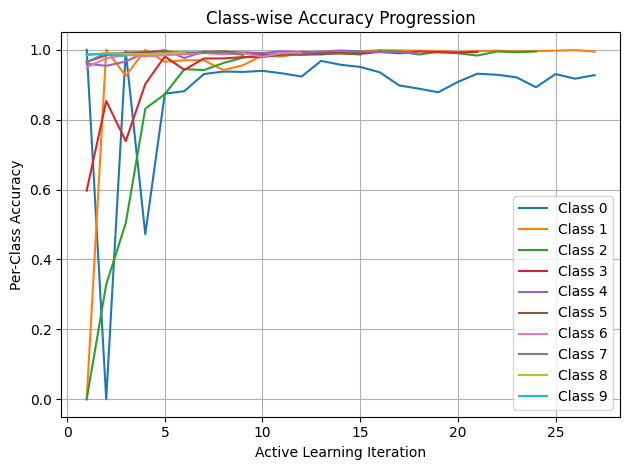

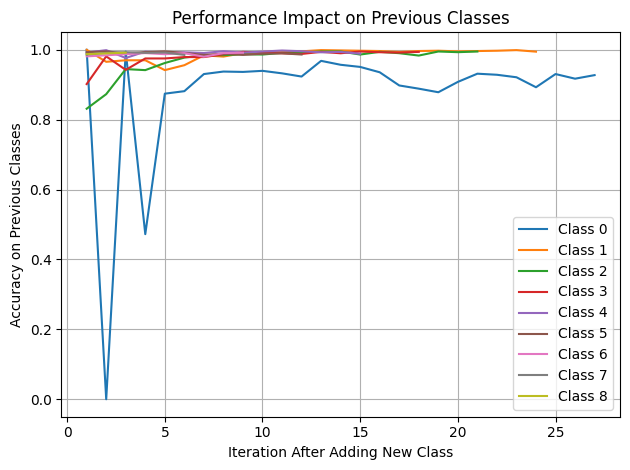

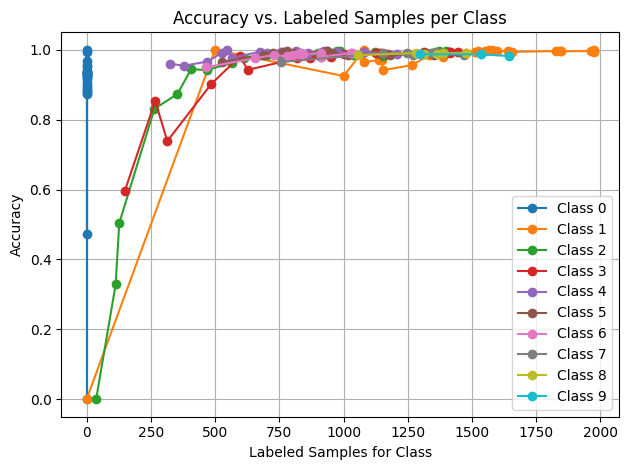


✅ Class Learning Iterations (95% threshold):
Class 1: learned in 2 iterations
Class 2: not yet reached 95% accuracy
Class 3: not yet reached 95% accuracy
Class 4: learned in 1 iterations
Class 5: learned in 1 iterations
Class 6: learned in 2 iterations
Class 7: learned in 1 iterations
Class 8: learned in 1 iterations
Class 9: learned in 1 iterations

🔍 Per-class labeling summary:
Class 0: 0 / 5923 samples labeled (0.00%)
Class 1: 2117 / 6742 samples labeled (31.40%)
Class 2: 1401 / 5958 samples labeled (23.51%)
Class 3: 1447 / 6131 samples labeled (23.60%)
Class 4: 1229 / 5842 samples labeled (21.04%)
Class 5: 1374 / 5421 samples labeled (25.35%)
Class 6: 1033 / 5918 samples labeled (17.46%)
Class 7: 1671 / 6265 samples labeled (26.67%)
Class 8: 1481 / 5851 samples labeled (25.31%)
Class 9: 1747 / 5949 samples labeled (29.37%)


In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import transforms
from datasets import load_dataset
import numpy as np
import random
import os
import logging
import matplotlib.pyplot as plt

from torchvision.datasets import MNIST
from torchvision.datasets.folder import default_loader
from torchvision.datasets.utils import download_url
from torchvision.datasets.vision import VisionDataset
from PIL import Image

# Set up logging
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

def set_all_seeds(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)
    logger.info(f"All random seeds have been set to {seed}.")

set_all_seeds()


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3)
        self.fc1 = nn.Linear(64 * 5 * 5, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 64 * 5 * 5)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

def uncertainty_sampling(model, unlabeled_loader, n):
    model.eval()
    uncertainties = []
    all_indices = []
    with torch.no_grad():
        for x, _, idx in unlabeled_loader:
            x = x.to(device)
            output = F.softmax(model(x), dim=1)
            entropy = -torch.sum(output * torch.log(output + 1e-10), dim=1)
            uncertainties.extend(entropy.cpu().numpy())
            all_indices.extend(idx.numpy())
    sorted_idx = np.argsort(uncertainties)[-n:]
    return np.array(all_indices)[sorted_idx]

def evaluate_per_class_accuracy(model, test_loader):
    model.eval()
    class_correct = [0] * 10
    class_total = [0] * 10
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            outputs = model(x)
            _, predicted = torch.max(outputs, 1)
            c = (predicted == y).squeeze()
            for i in range(len(y)):
                label = y[i]
                class_correct[label] += c[i].item()
                class_total[label] += 1
    return [class_correct[i] / class_total[i] if class_total[i] > 0 else 0.0 for i in range(10)]

# Dataset Loading with Class-Incremental Setup
transform = transforms.Compose([transforms.ToTensor()])
train_set = MNIST(root='./data', train=True, download=True, transform=transform)
test_set = MNIST(root='./data', train=False, download=True, transform=transform)

# Prepare dataset with index tracking
class IndexedMNIST(MNIST):
    def __getitem__(self, index):
        data, target = super().__getitem__(index)
        return data, target, index

full_indexed = IndexedMNIST(root='./data', train=True, download=True, transform=transform)

# Training function
def train(model, loader, optimizer, criterion):
    model.train()
    for x, y, _ in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        output = model(x)
        loss = criterion(output, y)
        loss.backward()
        optimizer.step()

# Settings
model = SimpleCNN(num_classes=10).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)
batch_size = 64
query_size = 500
num_iterations = 3
accuracy_threshold = 0.95

included_classes = [0]
all_class_accuracies = {i: [] for i in range(10)}
class_learned_iter = {}
previous_class_impact = {i: [] for i in range(10)}
labeled_counts = {i: 0 for i in range(10)}
class_progress = {i: [] for i in range(10)}

labeled_indices = [i for i, (_, y) in enumerate(train_set) if y == 0][:100]
unlabeled_indices = [i for i, (_, y) in enumerate(train_set) if y != 0]

# Count total samples per class for reporting
total_per_class = {i: len([1 for _, y in train_set if y == i]) for i in range(10)}

test_loader = torch.utils.data.DataLoader(test_set, batch_size=64, shuffle=False)

# Active Learning Loop
for new_class in range(1, 10):
    logger.info(f"\n🔁 Adding class {new_class}")
    if new_class not in included_classes:
        new_class_indices = [i for i, (_, y) in enumerate(train_set) if y == new_class]
        unlabeled_indices.extend(new_class_indices)
        included_classes.append(new_class)

    for iter in range(num_iterations):
        logger.info(f"\n🚀 Iteration {iter + 1} with classes {included_classes}")
        labeled_subset = torch.utils.data.Subset(full_indexed, labeled_indices)
        train_loader = torch.utils.data.DataLoader(labeled_subset, batch_size=batch_size, shuffle=True)

        train(model, train_loader, optimizer, criterion)
        class_accuracies = evaluate_per_class_accuracy(model, test_loader)

        for cls in included_classes:
            acc = class_accuracies[cls]
            all_class_accuracies[cls].append(acc)
            class_progress[cls].append((acc, labeled_counts[cls]))
            logger.info(f"Accuracy on class {cls}: {acc:.4f}")

            if cls == new_class and cls not in class_learned_iter and acc >= accuracy_threshold:
                class_learned_iter[cls] = iter + 1

            if cls != new_class:
                previous_class_impact[cls].append(acc)

        unlabeled_subset = torch.utils.data.Subset(full_indexed, unlabeled_indices)
        unlabeled_loader = torch.utils.data.DataLoader(unlabeled_subset, batch_size=batch_size, shuffle=False)

        queried = uncertainty_sampling(model, unlabeled_loader, query_size)
        labels_of_queried = [train_set[i][1] for i in queried]
        for label in labels_of_queried:
            labeled_counts[label] += 1

        labeled_indices.extend(queried)
        unlabeled_indices = [idx for idx in unlabeled_indices if idx not in queried]

# Plot accuracy progression for each class
for cls, accs in all_class_accuracies.items():
    if accs:
        plt.plot(range(1, len(accs) + 1), accs, label=f"Class {cls}")

plt.xlabel("Active Learning Iteration")
plt.ylabel("Per-Class Accuracy")
plt.title("Class-wise Accuracy Progression")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot previous class impact
for cls, accs in previous_class_impact.items():
    if accs:
        plt.plot(range(1, len(accs) + 1), accs, label=f"Class {cls}")

plt.xlabel("Iteration After Adding New Class")
plt.ylabel("Accuracy on Previous Classes")
plt.title("Performance Impact on Previous Classes")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot Accuracy vs. Labeled Count per Class
for cls, history in class_progress.items():
    if history:
        accs, counts = zip(*history)
        plt.plot(counts, accs, marker='o', label=f"Class {cls}")

plt.xlabel("Labeled Samples for Class")
plt.ylabel("Accuracy")
plt.title("Accuracy vs. Labeled Samples per Class")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Report how many iterations were needed to learn each class
print("\n✅ Class Learning Iterations (95% threshold):")
for cls in range(1, 10):
    iter_learned = class_learned_iter.get(cls, None)
    if iter_learned:
        print(f"Class {cls}: learned in {iter_learned} iterations")
    else:
        print(f"Class {cls}: not yet reached 95% accuracy")

# Report percentage of labeled samples used per class
print("\n🔍 Per-class labeling summary:")
for cls in range(10):
    used = labeled_counts[cls]
    total = total_per_class[cls]
    pct = 100.0 * used / total if total > 0 else 0.0
    print(f"Class {cls}: {used} / {total} samples labeled ({pct:.2f}%)")
